In [95]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import geopandas as gpd
from pathlib import Path
import rasterio
from rasterio.plot import show
from matplotlib_scalebar.scalebar import ScaleBar


In [119]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

population_file = PROCESSED_DATA_DIR / "ghana_district_population_2021.csv"


population_df = pd.read_csv(population_file)
district_df = population_df.copy()


In [118]:
import geopandas as gpd

shapefile_path = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "ghana_district_boundaries"
    / "District_261.shp"
)

districts_gdf = gpd.read_file(shapefile_path)

districts_gdf.head()

,Label,Region,District,geometry
0,Abura Asebu Kwamankese,Central,Abura Asebu Kwamankese,"POLYGON ((-1.1437 5.38852, -1.14374 5.38723, -..."
1,Ada East,Greater Accra,Ada East,"POLYGON ((0.67955 5.77087, 0.67952 5.77089, 0...."
2,Ada West,Greater Accra,Ada West,"POLYGON ((0.47935 6.00641, 0.47936 6.00598, 0...."
3,Agortime-Ziope,Volta,Agortime-Ziope,"POLYGON ((0.64233 6.63246, 0.64243 6.63225, 0...."
4,Adansi Asokwa,Ashanti,Adansi Asokwa,"POLYGON ((-1.43623 6.30419, -1.4357 6.3033, -1..."


In [10]:
print("Dataset shape:", districts_gdf.shape)

print("\nColumn names:")
print(districts_gdf.columns.tolist())

print("\nCoordinate Reference System:")
print(districts_gdf.crs)

print("\nGeometry types:")
print(districts_gdf.geometry.geom_type.value_counts())

print("\nMissing values:")
print(districts_gdf.isnull().sum())

Dataset shape: (261, 4)

Column names:
['Label', 'Region', 'District', 'geometry']

Coordinate Reference System:
EPSG:4326

Geometry types:
Polygon         260
MultiPolygon      1
Name: count, dtype: int64

Missing values:
Label       0
Region      0
District    0
geometry    0
dtype: int64


In [11]:
districts_gdf[["Region", "District", "Label"]].head(10)

,Region,District,Label
0,Central,Abura Asebu Kwamankese,Abura Asebu Kwamankese
1,Greater Accra,Ada East,Ada East
2,Greater Accra,Ada West,Ada West
3,Volta,Agortime-Ziope,Agortime-Ziope
4,Ashanti,Adansi Asokwa,Adansi Asokwa
5,Ashanti,Adansi South,Adansi South
6,Greater Accra,Adentan Municipal,Adentan Municipal
7,Volta,Afadzato South,Afadzato South
8,Ashanti,Afigya Kwabre North,Afigya Kwabre North
9,Central,Agona East,Agona East


In [12]:
# Create a separate dataset for district-level analysis
district_analysis = district_df.copy()

# Rank districts from highest to lowest population
district_analysis = district_analysis.sort_values(
    by="population",
    ascending=False
).reset_index(drop=True)

# Assign population ranking
district_analysis.insert(
    0,
    "rank",
    range(1, len(district_analysis) + 1)
)

# Display the top 10 most populated districts
print("TOP 10 MOST POPULATED DISTRICTS")
print("-" * 65)

display(district_analysis.head(10))

TOP 10 MOST POPULATED DISTRICTS
-----------------------------------------------------------------


,rank,region,district,population
0,1,Ashanti,Kumasi Metropolitan Area (KMA),443981
1,2,Greater Accra,Kpone Katamanso Municipal,412828
2,3,Northern,Tamale Metropolitan Area (TMA),374744
3,4,Greater Accra,Ga South Municipal,350121
4,5,Northern,Sagnarigu Municipal,341711
5,6,Greater Accra,Ga Central Municipal,332232
6,7,Greater Accra,Ga West Municipal,314299
7,8,Central,Gomoa East,308697
8,9,Ashanti,Kwabre East,296814
9,10,Greater Accra,Accra Metropolitan Area (AMA),284124


In [13]:
district_population_gdf = districts_gdf.merge(
    district_analysis,
    left_on=["Region", "District"],
    right_on=["region", "district"],
    how="left",
    validate="one_to_one"
)

district_population_gdf.head()

,Label,Region,District,geometry,rank,region,district,population
0,Abura Asebu Kwamankese,Central,Abura Asebu Kwamankese,"POLYGON ((-1.1437 5.38852, -1.14374 5.38723, -...",86,Central,Abura Asebu Kwamankese,124465
1,Ada East,Greater Accra,Ada East,"POLYGON ((0.67955 5.77087, 0.67952 5.77089, 0....",186,Greater Accra,Ada East,76411
2,Ada West,Greater Accra,Ada West,"POLYGON ((0.47935 6.00641, 0.47936 6.00598, 0....",189,Greater Accra,Ada West,76087
3,Agortime-Ziope,Volta,Agortime-Ziope,"POLYGON ((0.64233 6.63246, 0.64243 6.63225, 0....",249,Volta,Agortime-Ziope,39553
4,Adansi Asokwa,Ashanti,Adansi Asokwa,"POLYGON ((-1.43623 6.30419, -1.4357 6.3033, -1...",200,Ashanti,Adansi Asokwa,71844


In [14]:
print("Number of boundary records:", len(districts_gdf))
print("Number of joined records:", len(district_population_gdf))

print(
    "Districts without population data:",
    district_population_gdf["population"].isna().sum()
)

print(
    "Districts with population data:",
    district_population_gdf["population"].notna().sum()
)

Number of boundary records: 261
Number of joined records: 261
Districts without population data: 0
Districts with population data: 261


In [15]:
print(
    "Total population from original dataset:",
    district_analysis["population"].sum()
)

print(
    "Total population after spatial join:",
    district_population_gdf["population"].sum()
)

Total population from original dataset: 30832019
Total population after spatial join: 30832019


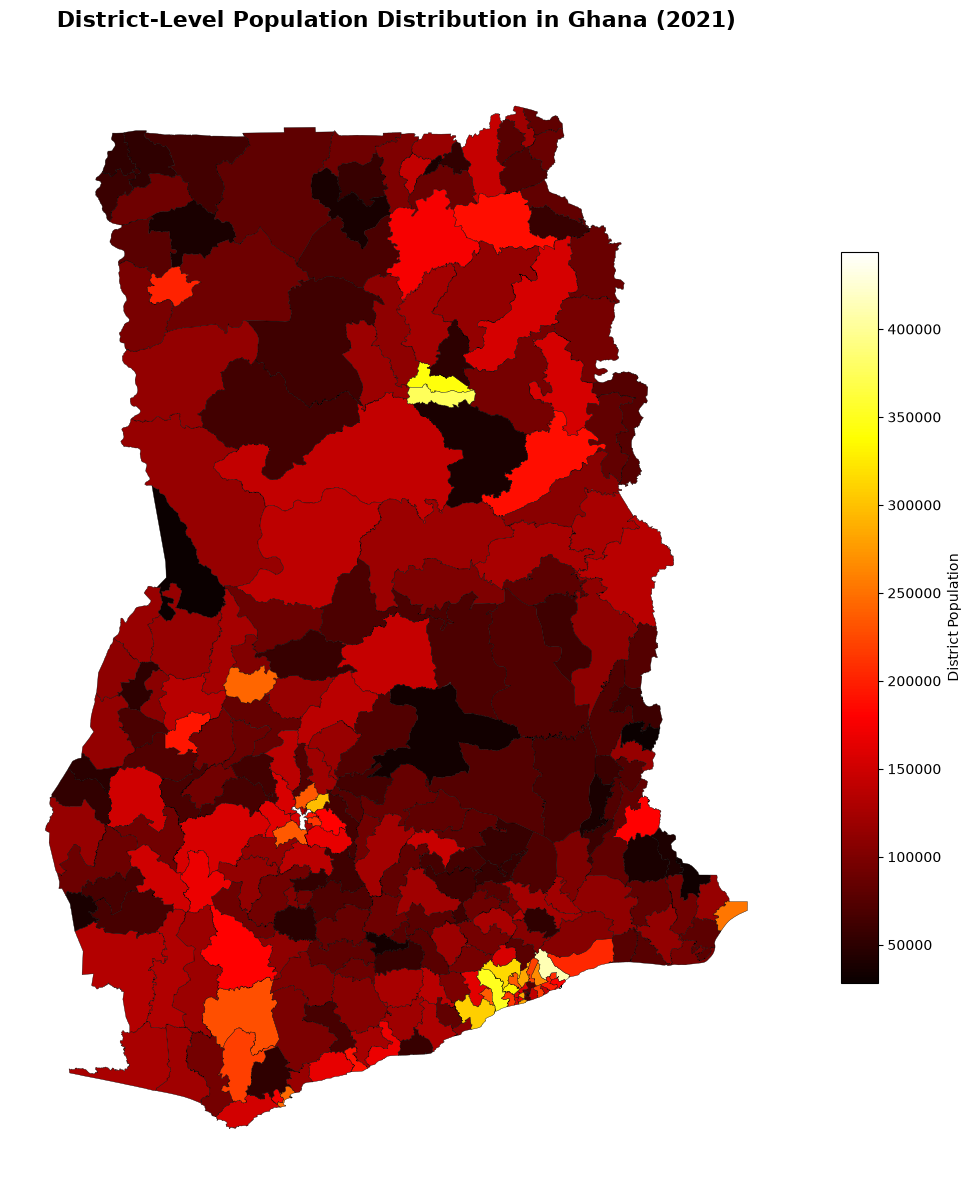

In [18]:
fig, ax = plt.subplots(figsize=(12, 12))

district_population_gdf.plot(
    column="population",
    cmap="hot",
    linewidth=0.25,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "District Population",
        "orientation": "vertical",
        "shrink": 0.65
    },
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "Missing population data"
    }
)

ax.set_title(
    "District-Level Population Distribution in Ghana (2021)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

output_dir = PROJECT_ROOT / "outputs" / "maps"

population_map_path = (
    output_dir / "ghana_district_population_distribution.png"
)

fig.savefig(
    population_map_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [19]:
districts_projected = district_population_gdf.to_crs(epsg=32630)

districts_projected.head()

,Label,Region,District,geometry,rank,region,district,population
0,Abura Asebu Kwamankese,Central,Abura Asebu Kwamankese,"POLYGON ((705688.008 595923.892, 705684.996 59...",86,Central,Abura Asebu Kwamankese,124465
1,Ada East,Greater Accra,Ada East,"POLYGON ((907656.573 639194.103, 907653.658 63...",186,Greater Accra,Ada East,76411
2,Ada West,Greater Accra,Ada West,"POLYGON ((885286.9 665138.27, 885287.599 66509...",189,Greater Accra,Ada West,76087
3,Agortime-Ziope,Volta,Agortime-Ziope,"POLYGON ((902871.602 734599.003, 902882.987 73...",249,Volta,Agortime-Ziope,39553
4,Adansi Asokwa,Ashanti,Adansi Asokwa,"POLYGON ((672983.887 697089.692, 673042.825 69...",200,Ashanti,Adansi Asokwa,71844


In [20]:
districts_projected["area_km2"] = (
    districts_projected.geometry.area / 1_000_000
)

districts_projected[
    ["Region", "District", "area_km2"]
].head(10)

,Region,District,area_km2
0,Central,Abura Asebu Kwamankese,386.450502
1,Greater Accra,Ada East,297.916939
2,Greater Accra,Ada West,326.504226
3,Volta,Agortime-Ziope,322.788975
4,Ashanti,Adansi Asokwa,734.497548
5,Ashanti,Adansi South,767.174512
6,Greater Accra,Adentan Municipal,79.123047
7,Volta,Afadzato South,524.090545
8,Ashanti,Afigya Kwabre North,268.183889
9,Central,Agona East,318.246197


In [21]:
districts_projected["population_density"] = (
    districts_projected["population"] /
    districts_projected["area_km2"]
)

districts_projected[
    ["Region", "District", "population", "area_km2", "population_density"]
].head(10)

,Region,District,population,area_km2,population_density
0,Central,Abura Asebu Kwamankese,124465,386.450502,322.072295
1,Greater Accra,Ada East,76411,297.916939,256.484241
2,Greater Accra,Ada West,76087,326.504226,233.035269
3,Volta,Agortime-Ziope,39553,322.788975,122.535164
4,Ashanti,Adansi Asokwa,71844,734.497548,97.813805
5,Ashanti,Adansi South,85200,767.174512,111.056870
6,Greater Accra,Adentan Municipal,265971,79.123047,3361.485815
7,Volta,Afadzato South,73146,524.090545,139.567486
8,Ashanti,Afigya Kwabre North,73330,268.183889,273.431787
9,Central,Agona East,98637,318.246197,309.939289


In [22]:
districts_projected["population_density"].describe()

count      261.000000
mean      1215.359612
std       3364.032100
min          9.709121
25%         83.632237
50%        146.368357
75%        367.192191
max      29432.235567
Name: population_density, dtype: float64

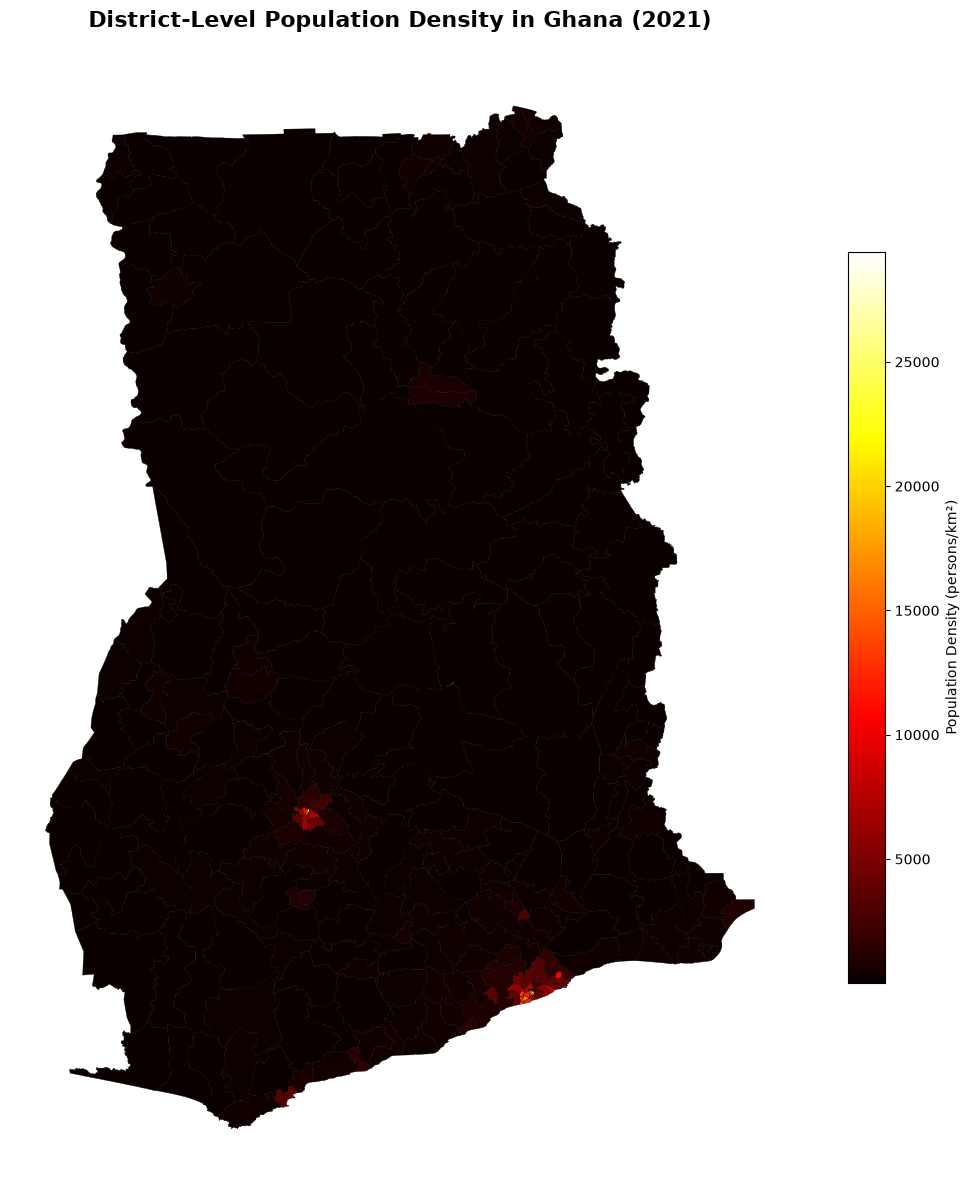

In [23]:
fig, ax = plt.subplots(figsize=(12, 12))

districts_projected.plot(
    column="population_density",
    cmap="hot",
    linewidth=0.25,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "Population Density (persons/km²)",
        "orientation": "vertical",
        "shrink": 0.65
    },
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "Missing data"
    }
)

ax.set_title(
    "District-Level Population Density in Ghana (2021)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

density_map_path = (
    output_dir / "ghana_district_population_density.png"
)

fig.savefig(
    density_map_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [24]:
density_ranking = (
    districts_projected[
        ["Region", "District", "population", "area_km2", "population_density"]
    ]
    .sort_values(
        by="population_density",
        ascending=False
    )
    .reset_index(drop=True)
)

density_ranking.insert(
    0,
    "rank",
    range(1, len(density_ranking) + 1)
)

density_ranking.head(10)

,rank,Region,District,population,area_km2,population_density
0,1,Greater Accra,Ayawaso North Municipal,63386,2.153625,29432.235567
1,2,Ashanti,Old Tafo Municipal,114368,5.449326,20987.549633
2,3,Greater Accra,Ablekuma Central Municipal,169145,10.095991,16753.679839
3,4,Greater Accra,Ayawaso Central Municipal,94831,6.456376,14687.961012
4,5,Greater Accra,Ayawaso East Municipal,53004,3.665810,14459.012611
5,6,Greater Accra,Ablekuma North Municipal,159208,12.106906,13150.180576
6,7,Greater Accra,Ablekuma West Municipal,153490,11.928342,12867.672815
7,8,Greater Accra,Accra Metropolitan Area (AMA),284124,23.330255,12178.349324
8,9,Greater Accra,Ashaiman Municipal,208060,19.578260,10627.093551
9,10,Ashanti,Suame Municipal,136290,12.828594,10623.923438


In [25]:
density_ranking.tail(10)

,rank,Region,District,population,area_km2,population_density
251,252,Upper West,Wa East,91457,4331.212908,21.115794
252,253,Savannah,Central Gonja,142762,7363.302148,19.388312
253,254,Savannah,Bole,115800,6222.497206,18.609892
254,255,Bono East,Sene East,72081,4301.380179,16.757645
255,256,Upper West,Sissala East Municipal,80619,5098.704563,15.811663
256,257,Savannah,West Gonja,63449,4689.903638,13.528849
257,258,Bono,Banda,28179,2132.026086,13.217005
258,259,Savannah,North Gonja,61443,4870.412938,12.615563
259,260,Savannah,North East Gonja,39404,3172.574972,12.420195
260,261,Ashanti,Sekyere Afram Plains,33226,3422.142945,9.709121


In [26]:
population_density_comparison = districts_projected[
    [
        "Region",
        "District",
        "population",
        "area_km2",
        "population_density"
    ]
].copy()

population_density_comparison.head()

,Region,District,population,area_km2,population_density
0,Central,Abura Asebu Kwamankese,124465,386.450502,322.072295
1,Greater Accra,Ada East,76411,297.916939,256.484241
2,Greater Accra,Ada West,76087,326.504226,233.035269
3,Volta,Agortime-Ziope,39553,322.788975,122.535164
4,Ashanti,Adansi Asokwa,71844,734.497548,97.813805


In [27]:
population_density_comparison["population_rank"] = (
    population_density_comparison["population"]
    .rank(method="min", ascending=False)
    .astype(int)
)

population_density_comparison["density_rank"] = (
    population_density_comparison["population_density"]
    .rank(method="min", ascending=False)
    .astype(int)
)

population_density_comparison.head()

,Region,District,population,area_km2,population_density,population_rank,density_rank
0,Central,Abura Asebu Kwamankese,124465,386.450502,322.072295,86,74
1,Greater Accra,Ada East,76411,297.916939,256.484241,186,91
2,Greater Accra,Ada West,76087,326.504226,233.035269,189,101
3,Volta,Agortime-Ziope,39553,322.788975,122.535164,249,144
4,Ashanti,Adansi Asokwa,71844,734.497548,97.813805,200,179


In [28]:
population_density_comparison["rank_difference"] = (
    population_density_comparison["population_rank"]
    - population_density_comparison["density_rank"]
)

population_density_comparison.sort_values(
    by="rank_difference",
    ascending=False
).head(10)

,Region,District,population,area_km2,population_density,population_rank,density_rank,rank_difference
22,Greater Accra,Ayawaso East Municipal,53004,3.665810,14459.012611,240,5,235
217,Greater Accra,Ayawaso North Municipal,63386,2.153625,29432.235567,221,1,220
197,Upper East,Bolgatanga East,38824,70.848628,547.985208,252,56,196
25,Greater Accra,Korle Klottey Municipal,68633,11.913184,5761.096185,207,17,190
23,Greater Accra,Ayawaso West Municipal,75303,34.952406,2154.443983,190,34,156
216,Ashanti,Adansi North,54155,230.110543,235.343411,237,99,138
21,Greater Accra,Ayawaso Central Municipal,94831,6.456376,14687.961012,141,4,137
247,Eastern,Birim Central Municipal,76302,122.706651,621.824485,187,52,135
249,Eastern,Birim South,35654,231.728268,153.861246,257,123,134
127,Upper East,Nabdam,53039,245.399800,216.133020,239,105,134


In [29]:
population_density_comparison.sort_values(
    by="rank_difference",
    ascending=True
).head(10)

,Region,District,population,area_km2,population_density,population_rank,density_rank,rank_difference
64,Savannah,Central Gonja,142762,7363.302148,19.388312,64,253,-189
101,Bono East,Kintampo North Municipal,140250,4921.343963,28.498313,67,245,-178
84,Northern,Gushegu Municipal,153965,2841.805264,54.178589,55,232,-177
192,North East,West Mamprusi Municipal,175755,2603.559093,67.505670,39,216,-177
40,Bono East,Atebubu Amantin Municipal,144947,2605.893260,55.622769,61,229,-168
130,Northern,Nanumba North Municipal,188680,2386.707891,79.054500,33,201,-168
28,Western North,Aowin Municipal,133257,2601.251633,51.228031,75,233,-158
136,Oti,Nkwanta South Municipal,135936,2508.559324,54.188872,74,231,-157
56,Savannah,Bole,115800,6222.497206,18.609892,105,254,-149
196,Savannah,East Gonja Municipal,117755,4247.856807,27.721038,98,246,-148


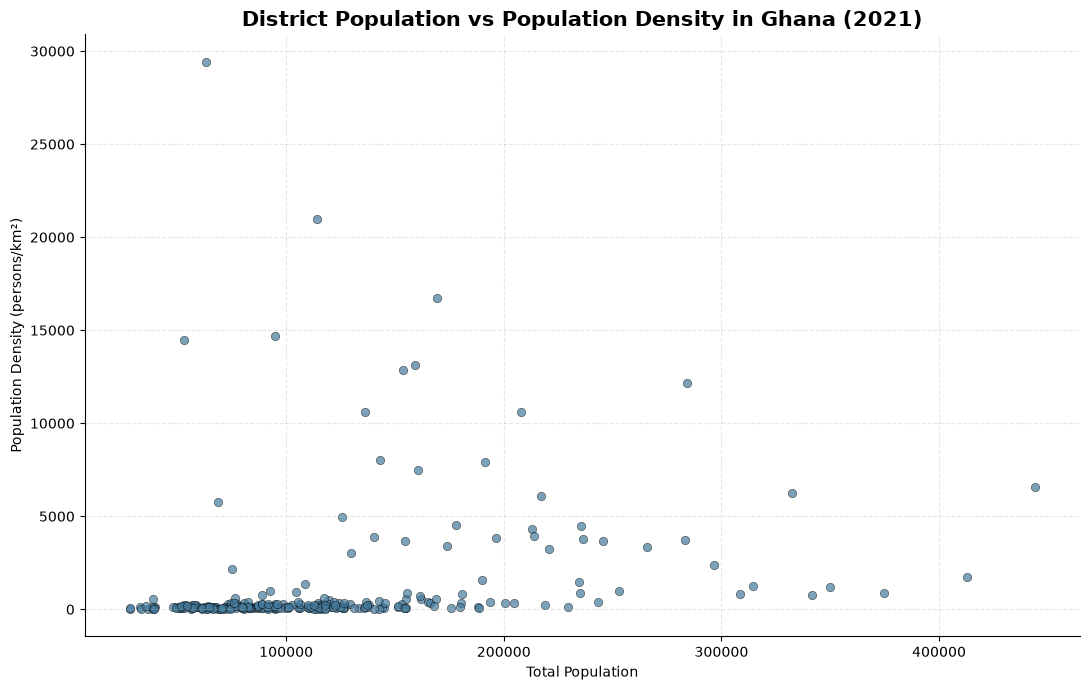

In [43]:
fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    population_density_comparison["population"],
    population_density_comparison["population_density"],
    alpha=0.7,
    color="#457B9D",
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    "District Population vs Population Density in Ghana (2021)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Total Population")
ax.set_ylabel("Population Density (persons/km²)")

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

comparison_chart_path = (
    output_dir / "population_vs_density_comparison.png"
)

fig.savefig(
    comparison_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [44]:
regional_density = (
    districts_projected
    .groupby("Region")
    .agg(
        population=("population", "sum"),
        area_km2=("area_km2", "sum")
    )
    .reset_index()
)

regional_density = regional_density.rename(
    columns={"Region": "region"}
)

regional_density = regional_density.sort_values(
    by="population",
    ascending=False
).reset_index(drop=True)

display(regional_density)

,region,population,area_km2
0,Greater Accra,5455692,3703.794659
1,Ashanti,5440463,24268.422198
2,Eastern,2925653,19493.016265
3,Central,2859821,9637.381208
4,Northern,2310928,25750.457233
5,Western,2060585,14219.609572
6,Volta,1659040,9304.463512
7,Upper East,1301226,8637.352676
8,Bono,1208649,11426.961633
9,Bono East,1203400,23560.125944


In [45]:
regional_density["population_density"] = (
    regional_density["population"] /
    regional_density["area_km2"]
)

regional_density["population_density"] = (
    regional_density["population_density"].round(2)
)

regional_density = regional_density.sort_values(
    by="population_density",
    ascending=False
).reset_index(drop=True)

regional_density.insert(
    0,
    "rank",
    range(1, len(regional_density) + 1)
)

display(regional_density)

,rank,region,population,area_km2,population_density
0,1,Greater Accra,5455692,3703.794659,1473.00
1,2,Central,2859821,9637.381208,296.74
2,3,Ashanti,5440463,24268.422198,224.18
3,4,Volta,1659040,9304.463512,178.31
4,5,Upper East,1301226,8637.352676,150.65
5,6,Eastern,2925653,19493.016265,150.09
6,7,Western,2060585,14219.609572,144.91
7,8,Ahafo,564668,5137.369568,109.91
8,9,Bono,1208649,11426.961633,105.77
9,10,Northern,2310928,25750.457233,89.74


In [46]:
print("Number of regions:", regional_density["region"].nunique())

print(
    "Total population:",
    f"{regional_density['population'].sum():,}"
)

print(
    "Total area:",
    f"{regional_density['area_km2'].sum():,.2f} km²"
)

print(
    "Duplicate regions:",
    regional_density["region"].duplicated().sum()
)

print(
    "Missing values:",
    regional_density.isna().sum().sum()
)

Number of regions: 16
Total population: 30,832,019
Total area: 239,116.87 km²
Duplicate regions: 0
Missing values: 0


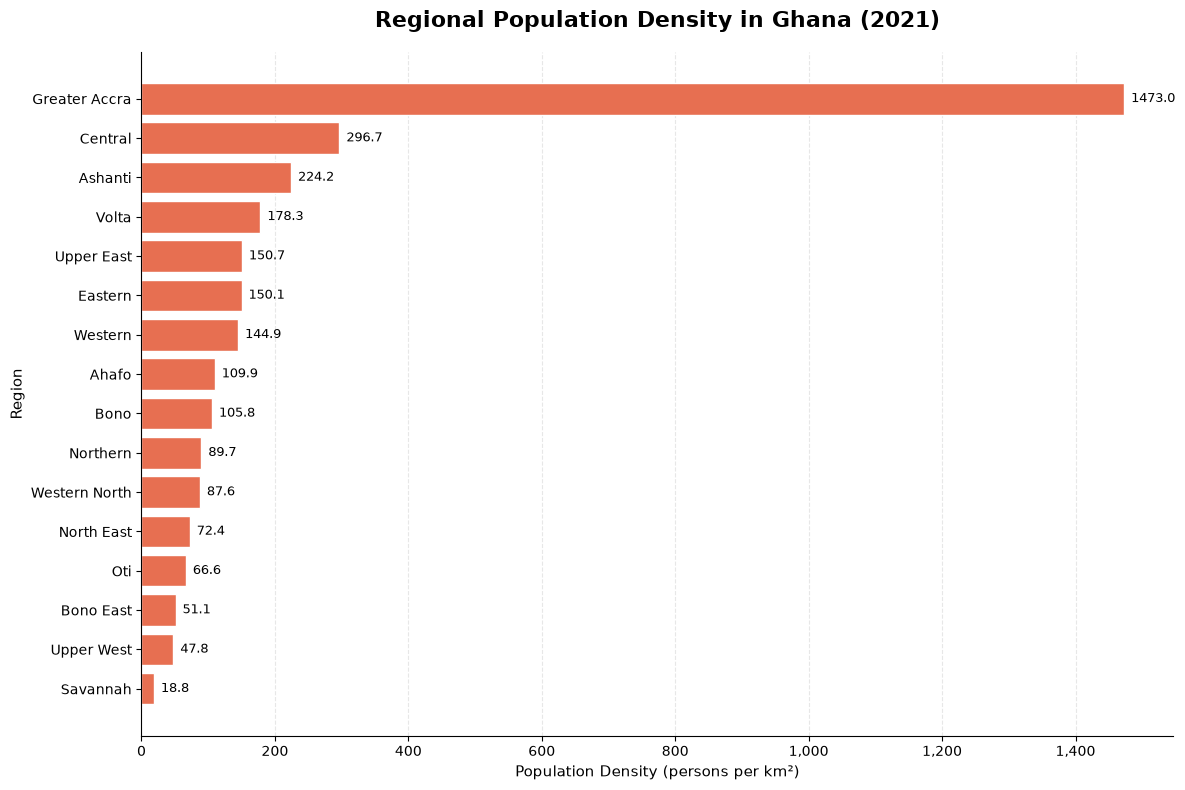

In [47]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 8), facecolor="white")

regional_density_sorted = regional_density.sort_values(
    by="population_density",
    ascending=True
)

bars = ax.barh(
    regional_density_sorted["region"],
    regional_density_sorted["population_density"],
    color="#E76F51",
    edgecolor="white"
)

ax.set_title(
    "Regional Population Density in Ghana (2021)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Population Density (persons per km²)", fontsize=11)
ax.set_ylabel("Region", fontsize=11)

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=5,
    fontsize=9
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()

# Save chart before displaying it
fig.savefig(
    output_dir / "regional_population_density.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [48]:
# Most densely populated region
highest_density = regional_density.iloc[0]

# Least densely populated region
lowest_density = regional_density.iloc[-1]

# Calculate density difference
density_difference = (
    highest_density["population_density"] -
    lowest_density["population_density"]
)

# Calculate density ratio
density_ratio = (
    highest_density["population_density"] /
    lowest_density["population_density"]
)

print("=" * 65)
print("       GHANA REGIONAL POPULATION DENSITY ANALYSIS (2021)")
print("=" * 65)

print("\nHIGHEST POPULATION DENSITY")
print("-" * 65)
print("Region:", highest_density["region"])
print(f"Population: {highest_density['population']:,}")
print(f"Area: {highest_density['area_km2']:,.2f} km²")
print(f"Density: {highest_density['population_density']:,.2f} persons/km²")

print("\nLOWEST POPULATION DENSITY")
print("-" * 65)
print("Region:", lowest_density["region"])
print(f"Population: {lowest_density['population']:,}")
print(f"Area: {lowest_density['area_km2']:,.2f} km²")
print(f"Density: {lowest_density['population_density']:,.2f} persons/km²")

print("\nDENSITY COMPARISON")
print("-" * 65)
print(f"Density difference: {density_difference:,.2f} persons/km²")
print(f"Density ratio: {density_ratio:.2f} times")

print("=" * 65)

       GHANA REGIONAL POPULATION DENSITY ANALYSIS (2021)

HIGHEST POPULATION DENSITY
-----------------------------------------------------------------
Region: Greater Accra
Population: 5,455,692
Area: 3,703.79 km²
Density: 1,473.00 persons/km²

LOWEST POPULATION DENSITY
-----------------------------------------------------------------
Region: Savannah
Population: 653,277
Area: 34,728.34 km²
Density: 18.81 persons/km²

DENSITY COMPARISON
-----------------------------------------------------------------
Density difference: 1,454.19 persons/km²
Density ratio: 78.31 times


In [49]:
top_5_density = regional_density.head(5).copy()
bottom_5_density = regional_density.tail(5).copy()

print("TOP 5 MOST DENSELY POPULATED REGIONS")
display(top_5_density)

print("BOTTOM 5 LEAST DENSELY POPULATED REGIONS")
display(bottom_5_density)

TOP 5 MOST DENSELY POPULATED REGIONS


,rank,region,population,area_km2,population_density
0,1,Greater Accra,5455692,3703.794659,1473.00
1,2,Central,2859821,9637.381208,296.74
2,3,Ashanti,5440463,24268.422198,224.18
3,4,Volta,1659040,9304.463512,178.31
4,5,Upper East,1301226,8637.352676,150.65


BOTTOM 5 LEAST DENSELY POPULATED REGIONS


,rank,region,population,area_km2,population_density
11,12,North East,658946,9100.279410,72.41
12,13,Oti,747248,11224.212565,66.57
13,14,Bono East,1203400,23560.125944,51.08
14,15,Upper West,901502,18869.417679,47.78
15,16,Savannah,653277,34728.343724,18.81


In [50]:
regional_comparison = regional_density[
    ["region", "population", "area_km2", "population_density"]
].copy()

regional_comparison["population_rank"] = (
    regional_comparison["population"]
    .rank(method="min", ascending=False)
    .astype(int)
)

regional_comparison["density_rank"] = (
    regional_comparison["population_density"]
    .rank(method="min", ascending=False)
    .astype(int)
)

regional_comparison["rank_difference"] = (
    regional_comparison["population_rank"] -
    regional_comparison["density_rank"]
)

regional_comparison = regional_comparison.sort_values(
    by="population_rank"
).reset_index(drop=True)

display(regional_comparison)

,region,population,area_km2,population_density,population_rank,density_rank,rank_difference
0,Greater Accra,5455692,3703.794659,1473.00,1,1,0
1,Ashanti,5440463,24268.422198,224.18,2,3,-1
2,Eastern,2925653,19493.016265,150.09,3,6,-3
3,Central,2859821,9637.381208,296.74,4,2,2
4,Northern,2310928,25750.457233,89.74,5,10,-5
5,Western,2060585,14219.609572,144.91,6,7,-1
6,Volta,1659040,9304.463512,178.31,7,4,3
7,Upper East,1301226,8637.352676,150.65,8,5,3
8,Bono,1208649,11426.961633,105.77,9,9,0
9,Bono East,1203400,23560.125944,51.08,10,14,-4


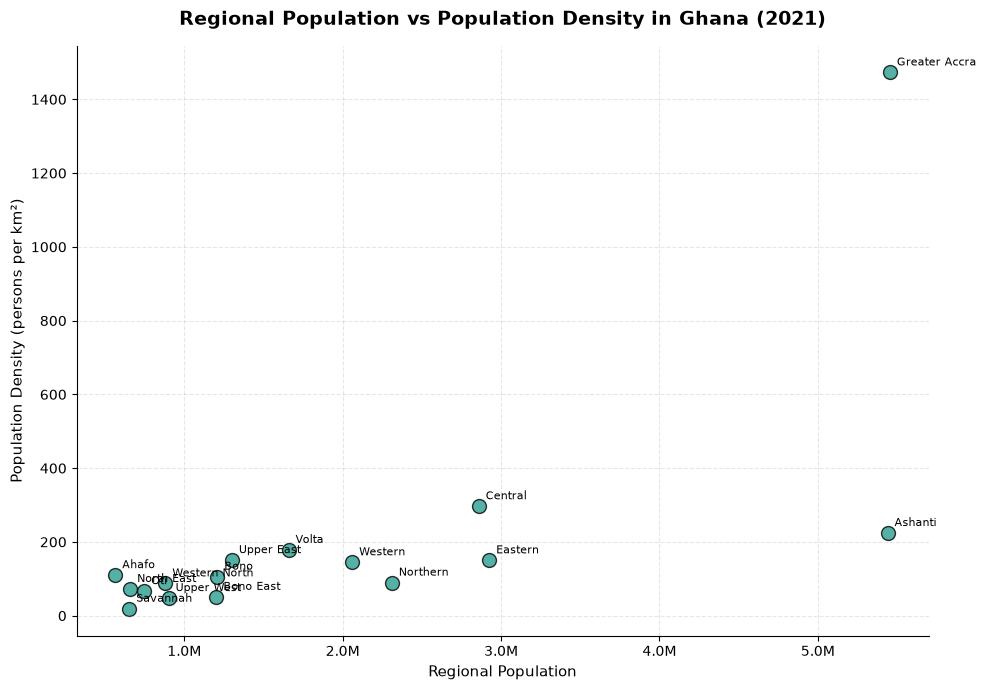

In [51]:
fig, ax = plt.subplots(figsize=(10, 7), facecolor="white")

ax.scatter(
    regional_comparison["population"],
    regional_comparison["population_density"],
    color="#2A9D8F",
    s=100,
    edgecolor="black",
    alpha=0.8
)

for _, row in regional_comparison.iterrows():
    ax.annotate(
        row["region"],
        (row["population"], row["population_density"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "Regional Population vs Population Density in Ghana (2021)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Regional Population", fontsize=11)
ax.set_ylabel("Population Density (persons per km²)", fontsize=11)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)

ax.grid(linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    output_dir / "regional_population_vs_density.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [59]:
raster_path = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "GHA_population_v2_0_gridded_population.tif"
)
 

with rasterio.open(raster_path) as src:
    print("CRS:", src.crs)
    print("Raster dimensions:", src.width, "x", src.height)
    print("Number of bands:", src.count)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("NoData value:", src.nodata)
    print("Data type:", src.dtypes)

with rasterio.open(raster_path) as src:
    population_raster = src.read(1, masked=True)

print("Raster shape:", population_raster.shape)
print("Minimum population:", population_raster.min())
print("Maximum population:", population_raster.max())
print("Mean population:", population_raster.mean())
print("Valid pixels:", population_raster.count())
print("Masked pixels:", population_raster.mask.sum())

CRS: EPSG:4326
Raster dimensions: 5337 x 7721
Number of bands: 1
Resolution: (0.000833333329960652, 0.0008333333300090661)
Bounds: BoundingBox(left=-3.255416639, bottom=4.738750182, right=1.1920833430000002, top=11.172916823)
NoData value: -3.3999999521443642e+38
Data type: ('float32',)
Raster shape: (7721, 5337)
Minimum population: 1.1976
Maximum population: 888.643
Mean population: 21.23753980254494
Valid pixels: 1568053
Masked pixels: 39638924


In [60]:
print("Raster shape:", population_raster.shape)

print("Minimum value:", np.nanmin(population_raster))

print("Maximum value:", np.nanmax(population_raster))

print("NoData / invalid pixels:",
      np.sum(~np.isfinite(population_raster)))

print("Zero or negative pixels:",
      np.sum(population_raster <= 0))

print("Positive population pixels:",
      np.sum(population_raster > 0))

Raster shape: (7721, 5337)
Minimum value: 1.1976
Maximum value: 888.643
NoData / invalid pixels: 0
Zero or negative pixels: 0
Positive population pixels: 1568053


In [61]:
population_masked = np.ma.masked_where(
    (~np.isfinite(population_raster)) |
    (population_raster <= 0),
    population_raster
)

print("Original raster shape:", population_raster.shape)

print("Masked raster shape:", population_masked.shape)

print(
    "Valid population pixels:",
    population_masked.count()
)

print(
    "Masked pixels:",
    population_masked.size - population_masked.count()
)

print(
    "Maximum valid population value:",
    f"{population_masked.max():,.2f}"
)

Original raster shape: (7721, 5337)
Masked raster shape: (7721, 5337)
Valid population pixels: 1568053
Masked pixels: 39638924
Maximum valid population value: 888.64


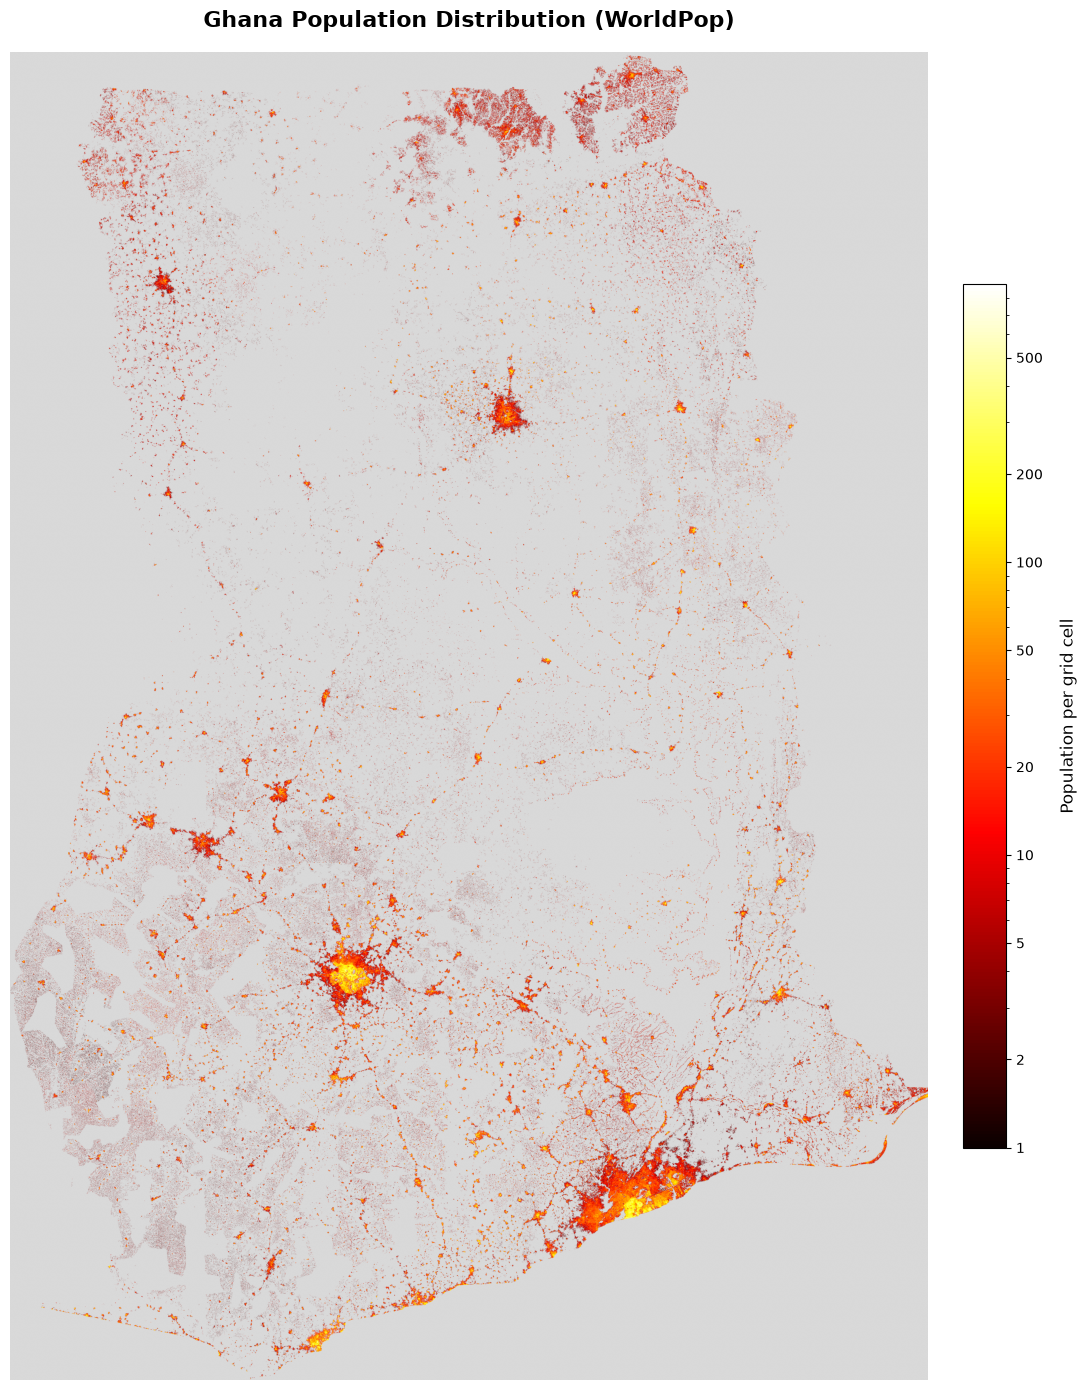

In [63]:
from matplotlib.colors import LogNorm

# Create a copy of the hot colour map
cmap = plt.colormaps["hot"].copy()

# Assign a distinct colour to masked pixels
cmap.set_bad("#D9D9D9")

# Determine the maximum valid population value
raster_max = float(population_masked.max())

# Create figure
fig, ax = plt.subplots(
    figsize=(12, 14),
    facecolor="white"
)

# Display raster
im = ax.imshow(
    population_masked,
    cmap=cmap,
    norm=LogNorm(
        vmin=1,
        vmax=raster_max
    )
)

# Add colour bar
cbar = fig.colorbar(
    im,
    ax=ax,
    shrink=0.65,
    pad=0.03
)

cbar.set_label(
    "Population per grid cell",
    fontsize=12,
    labelpad=12
)

# Add meaningful legend ticks within the raster value range
ticks = [1, 2, 5, 10, 20, 50, 100, 200, 500]
ticks = [tick for tick in ticks if tick <= raster_max]

cbar.set_ticks(ticks)
cbar.set_ticklabels([str(tick) for tick in ticks])

# Title
ax.set_title(
    "Ghana Population Distribution (WorldPop)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_axis_off()

plt.tight_layout()


map_dir = Path.cwd().parent / "outputs" / "maps"
map_dir.mkdir(parents=True, exist_ok=True)

# Save before displaying
fig.savefig(
    map_dir / "ghana_population_hot_raster_refined2.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [68]:
with rasterio.open(raster_path) as src:
    raster_bounds = src.bounds
    raster_crs = src.crs

print("Raster CRS:", raster_crs)
print("Raster bounds:", raster_bounds)
print("District CRS:", districts_gdf.crs)

Raster CRS: EPSG:4326
Raster bounds: BoundingBox(left=-3.255416639, bottom=4.738750182, right=1.1920833430000002, top=11.172916823)
District CRS: EPSG:4326


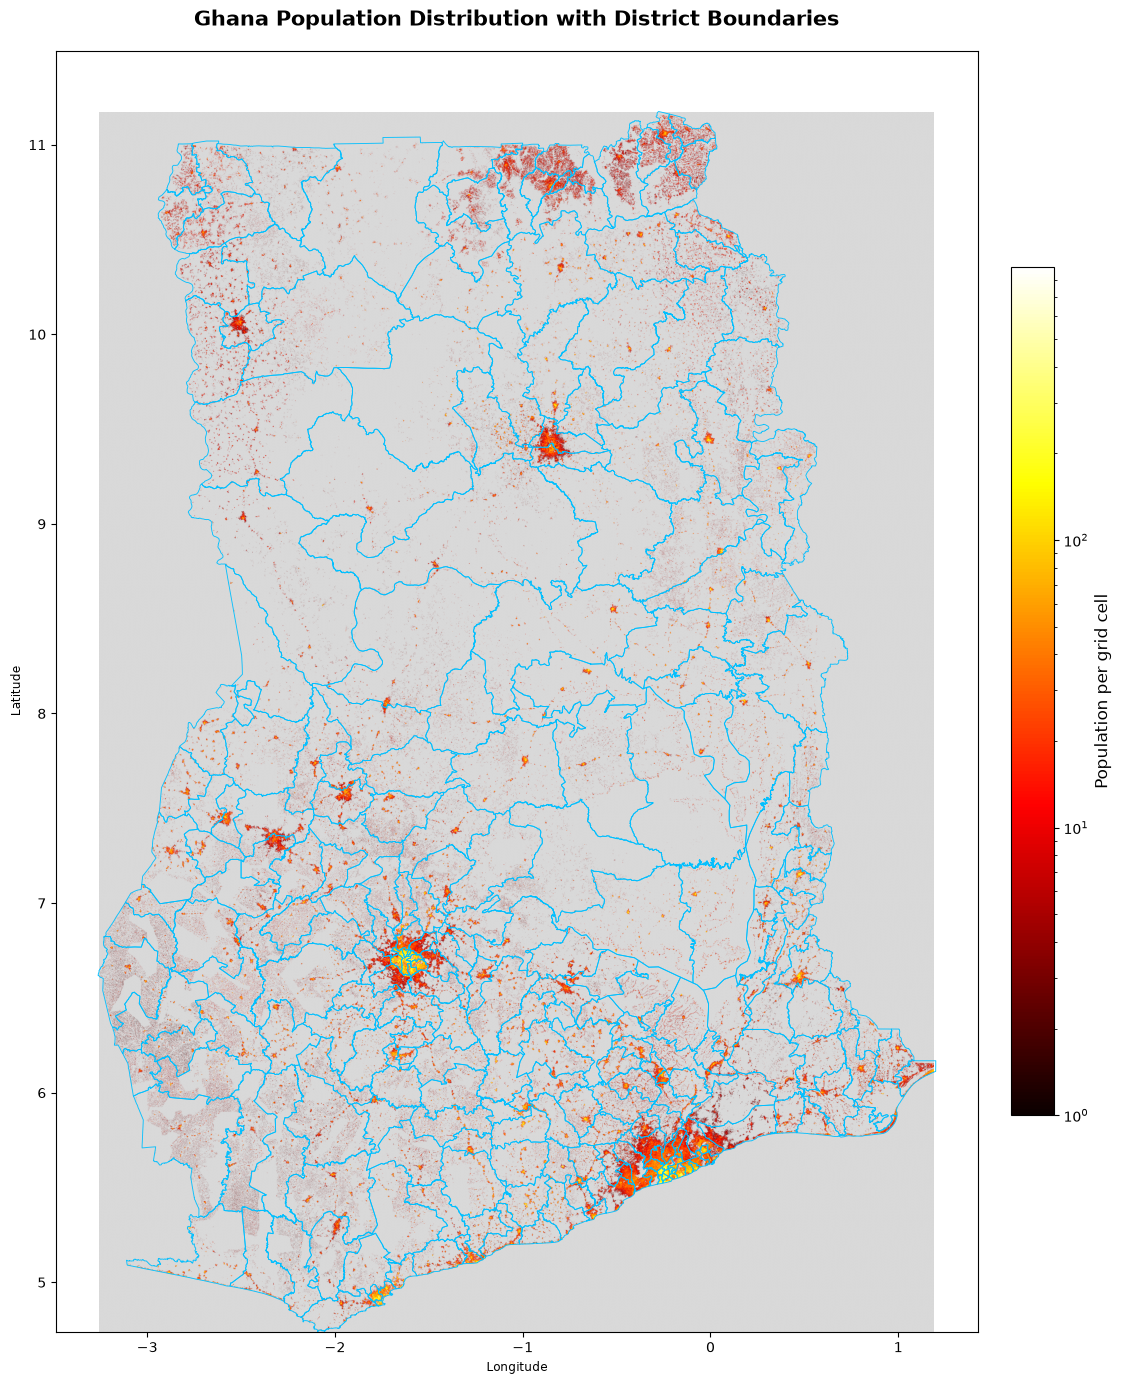

In [70]:
fig, ax = plt.subplots(
    figsize=(12, 14),
    facecolor="white"
)

im = ax.imshow(
    population_masked,
    cmap=cmap,
    norm=LogNorm(vmin=1, vmax=raster_max),
    extent=[
        raster_bounds.left,
        raster_bounds.right,
        raster_bounds.bottom,
        raster_bounds.top
    ],
    origin="upper"
)

districts_gdf.boundary.plot(
    ax=ax,
    color="#00BFFF",
    linewidth=0.65,
    alpha=0.95
)
cbar = fig.colorbar(
    im,
    ax=ax,
    shrink=0.65,
    pad=0.03
)

cbar.set_label("Population per grid cell", fontsize=12)

ax.set_title(
    "Ghana Population Distribution with District Boundaries",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()

fig.savefig(
    map_dir / "ghana_population_raster_district_boundaries.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [71]:
# Combine all administrative-area boundaries into one Ghana boundary
ghana_boundary = districts_gdf.dissolve()

# Inspect the resulting boundary
print("Number of boundary features:", len(ghana_boundary))
print("Coordinate Reference System:", ghana_boundary.crs)

display(ghana_boundary[["geometry"]])

Number of boundary features: 1
Coordinate Reference System: EPSG:4326


,geometry
0,"POLYGON ((-2.18081 4.81535, -2.1817 4.81587, -..."


In [72]:
from rasterio.mask import mask

# Open the original WorldPop raster
with rasterio.open(raster_path) as src:

    # Clip raster using Ghana's boundary
    ghana_raster, ghana_transform = mask(
        src,
        ghana_boundary.geometry,
        crop=True,
        nodata=src.nodata
    )

    # Capture raster metadata
    ghana_meta = src.meta.copy()

    ghana_meta.update({
        "height": ghana_raster.shape[1],
        "width": ghana_raster.shape[2],
        "transform": ghana_transform
    })

print("Clipped raster shape:", ghana_raster.shape)
print("Raster width:", ghana_meta["width"])
print("Raster height:", ghana_meta["height"])
print("Raster CRS:", ghana_meta["crs"])

Clipped raster shape: (1, 7721, 5337)
Raster width: 5337
Raster height: 7721
Raster CRS: EPSG:4326


In [120]:
# Create raster output directory
raster_output_dir = PROCESSED_DATA_DIR / "rasters"
raster_output_dir.mkdir(parents=True, exist_ok=True)

# Define output file
ghana_raster_path = (
    raster_output_dir / "ghana_population_clipped_2021.tif"
)

# Save clipped raster
with rasterio.open(
    ghana_raster_path,
    "w",
    **ghana_meta
) as dst:
    dst.write(ghana_raster)

print("Clipped raster saved successfully!")


Clipped raster saved successfully!


In [75]:
with rasterio.open(ghana_raster_path) as src:

    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bounds:", src.bounds)
    print("NoData value:", src.nodata)
    print("Number of bands:", src.count)

CRS: EPSG:4326
Width: 5337
Height: 7721
Bounds: BoundingBox(left=-3.255416639, bottom=4.738750182, right=1.1920833430000002, top=11.172916823)
NoData value: -3.3999999521443642e+38
Number of bands: 1


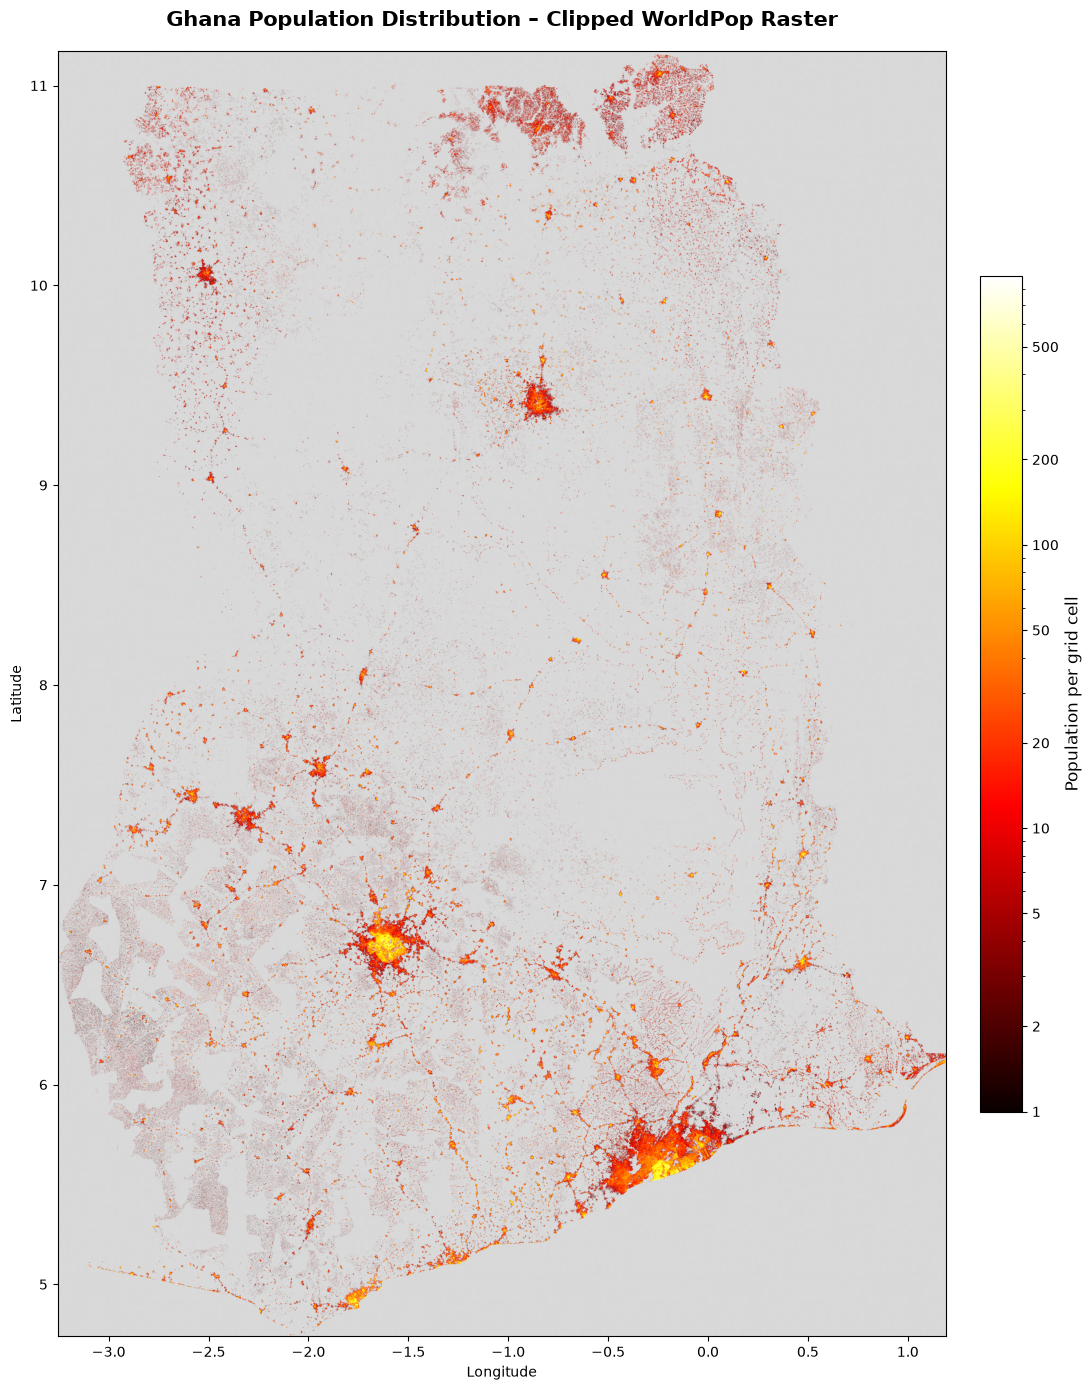

In [76]:
from matplotlib.colors import LogNorm

# Read the saved clipped raster
with rasterio.open(ghana_raster_path) as src:
    clipped_population = src.read(1, masked=True)
    clipped_bounds = src.bounds

# Mask zero, negative and invalid values
clipped_population = np.ma.masked_where(
    (~np.isfinite(clipped_population)) |
    (clipped_population <= 0),
    clipped_population
)

# Prepare colour map
clipped_cmap = plt.colormaps["hot"].copy()
clipped_cmap.set_bad("#D9D9D9")

# Get maximum valid population value
clipped_max = float(clipped_population.max())

# Create figure
fig, ax = plt.subplots(
    figsize=(12, 14),
    facecolor="white"
)

im = ax.imshow(
    clipped_population,
    cmap=clipped_cmap,
    norm=LogNorm(vmin=1, vmax=clipped_max),
    extent=[
        clipped_bounds.left,
        clipped_bounds.right,
        clipped_bounds.bottom,
        clipped_bounds.top
    ],
    origin="upper"
)

# Add colour bar
cbar = fig.colorbar(
    im,
    ax=ax,
    shrink=0.65,
    pad=0.03
)

cbar.set_label(
    "Population per grid cell",
    fontsize=12
)

ticks = [
    tick for tick in [1, 2, 5, 10, 20, 50, 100, 200, 500]
    if tick <= clipped_max
]

cbar.set_ticks(ticks)
cbar.set_ticklabels([str(tick) for tick in ticks])

ax.set_title(
    "Ghana Population Distribution – Clipped WorldPop Raster",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()

fig.savefig(
    map_dir / "ghana_population_clipped_raster.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [77]:
print("Clipped raster shape:", clipped_population.shape)

print(
    "Valid population pixels:",
    clipped_population.count()
)

print(
    "Masked pixels:",
    clipped_population.size - clipped_population.count()
)

print(
    "Maximum population per grid cell:",
    f"{clipped_population.max():,.2f}"
)

Clipped raster shape: (7721, 5337)
Valid population pixels: 1568014
Masked pixels: 39638963
Maximum population per grid cell: 888.64


In [82]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

# Prepare the clipped population raster
final_population = np.ma.masked_where(
    (~np.isfinite(clipped_population)) |
    (clipped_population <= 0),
    clipped_population
)

# Configure the hot colour map
final_cmap = plt.colormaps["hot"].copy()
final_cmap.set_bad("#D9D9D9")

# Determine the maximum population value
final_max = float(final_population.max())

print("Final raster prepared successfully.")
print("Raster shape:", final_population.shape)
print("Valid pixels:", final_population.count())
print("Maximum population:", final_max)

Final raster prepared successfully.
Raster shape: (7721, 5337)
Valid pixels: 1568014
Maximum population: 888.6430053710938


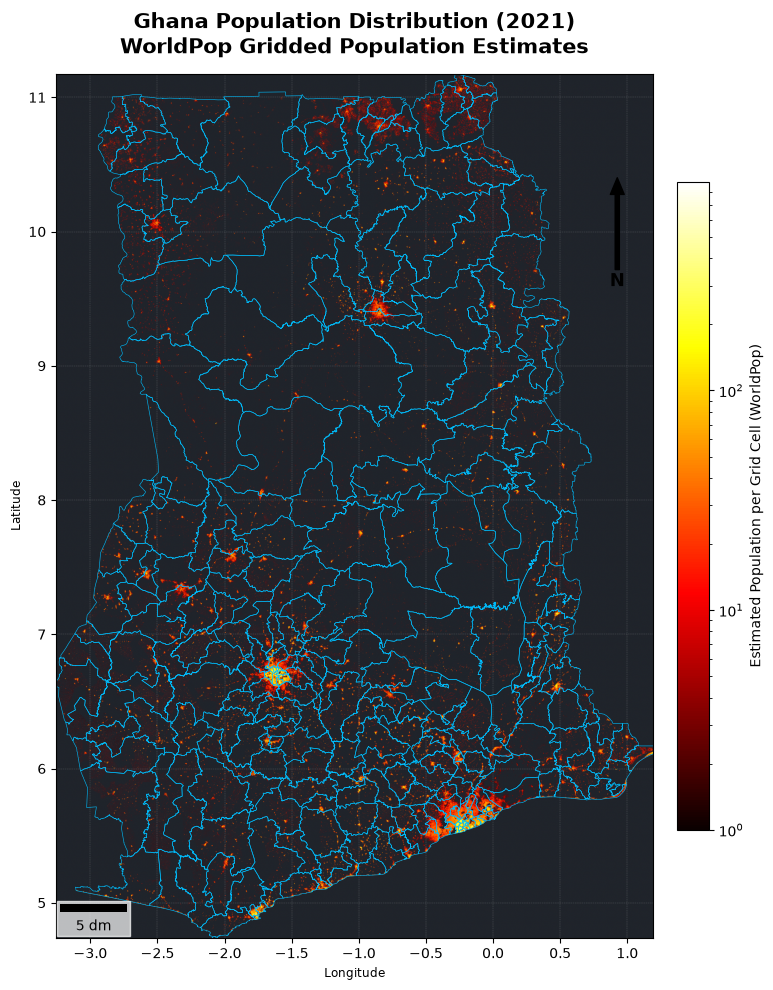

In [111]:
fig, ax = plt.subplots(figsize=(12, 10))

# Correct the raster extent for Matplotlib
raster_extent = (
    clipped_bounds.left,
    clipped_bounds.right,
    clipped_bounds.bottom,
    clipped_bounds.top
)

# Plot population raster
im = ax.imshow(
    final_population,
    cmap=final_cmap,
    norm=LogNorm(vmin=1, vmax=final_max),
    extent=raster_extent,
    origin="upper"
)

# Overlay district boundaries
districts_gdf.boundary.plot(
    ax=ax,
    color="#00BFFF",
    linewidth=0.45,
    alpha=0.9
)

# Set the correct map extent
ax.set_xlim(raster_extent[0], raster_extent[1])
ax.set_ylim(raster_extent[2], raster_extent[3])

# Add colour bar
cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
cbar.set_label(
    "Estimated Population per Grid Cell (WorldPop)",
    fontsize=10
)

# Map title
ax.set_title(
    "Ghana Population Distribution (2021)\nWorldPop Gridded Population Estimates",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.annotate(
    "N",
    xy=(0.94, 0.88),
    xytext=(0.94, 0.76),
    xycoords="axes fraction",
    textcoords="axes fraction",
    arrowprops=dict(
        facecolor="black",
        edgecolor="black",
        width=3,
        headwidth=10
    ),
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

scalebar = ScaleBar(
    dx=1,
    units="m",
    dimension="si-length",
    location="lower left",
    length_fraction=0.20,
    box_alpha=0.7,
    color="black",
    scale_loc="bottom"
)

ax.add_artist(scalebar)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_aspect("equal")
ax.grid(True, linestyle="--", linewidth=0.3, alpha=0.4)

plt.tight_layout()
plt.show()

In [121]:
# Ensure the output directory exists
output_dir.mkdir(parents=True, exist_ok=True)

# Define output path
final_map_path = output_dir / "ghana_worldpop_population_heatmap_2021.png"

# Save at high resolution
fig.savefig(
    final_map_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Map saved successfully!")

Map saved successfully!


In [122]:
from rasterio.warp import calculate_default_transform, reproject, Resampling
import rasterio

# Define output path
projected_raster_path = (
    PROCESSED_DATA_DIR / "rasters" /
    "ghana_population_projected_2021.tif"
)

with rasterio.open(ghana_raster_path) as src:

    # Calculate the new transform and raster dimensions
    dst_transform, dst_width, dst_height = calculate_default_transform(
        src.crs,
        "EPSG:32630",
        src.width,
        src.height,
        *src.bounds
    )

    # Update raster metadata
    dst_meta = src.meta.copy()
    dst_meta.update({
        "crs": "EPSG:32630",
        "transform": dst_transform,
        "width": dst_width,
        "height": dst_height,
        "nodata": src.nodata
    })

    # Create the projected raster
    with rasterio.open(projected_raster_path, "w", **dst_meta) as dst:

        for band in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, band),
                destination=rasterio.band(dst, band),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=dst_transform,
                dst_crs="EPSG:32630",
                resampling=Resampling.bilinear,
                src_nodata=src.nodata,
                dst_nodata=src.nodata
            )

print("Raster reprojected successfully!")


Raster reprojected successfully!


In [102]:
# Load projected raster
with rasterio.open(projected_raster_path) as src:
    projected_population = src.read(1, masked=True)
    projected_bounds = src.bounds
    projected_transform = src.transform
    projected_crs = src.crs

# Reproject district boundaries to match the raster
districts_projected_map = districts_gdf.to_crs(projected_crs)

# Mask invalid and zero population values
projected_population = np.ma.masked_where(
    (~np.isfinite(projected_population)) |
    (projected_population <= 0),
    projected_population
)

print("PROJECTED MAP DATA")
print("-" * 40)
print("Raster CRS:", projected_crs)
print("Raster shape:", projected_population.shape)
print("District CRS:", districts_projected_map.crs)
print("Raster bounds:", projected_bounds)
print("Valid pixels:", projected_population.count())

PROJECTED MAP DATA
----------------------------------------
Raster CRS: EPSG:32630
Raster shape: (7759, 5360)
District CRS: PROJCS["WGS 84 / UTM zone 30N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-3],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32630"]]
Raster bounds: BoundingBox(left=471674.9346554405, bottom=523775.94013976783, right=965310.6401486632, top=1238350.4623266922)
Valid pixels: 1567396


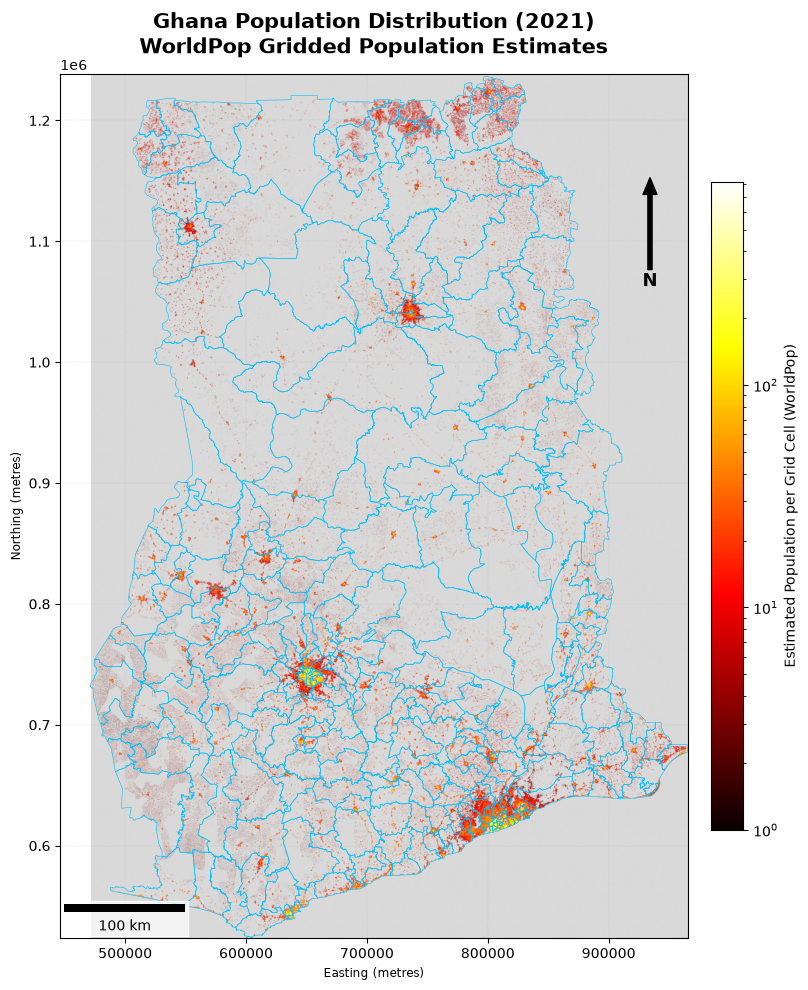

In [103]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(12, 10))

# Prepare raster extent
projected_extent = (
    projected_bounds.left,
    projected_bounds.right,
    projected_bounds.bottom,
    projected_bounds.top
)

# Plot population raster
im = ax.imshow(
    projected_population,
    cmap=final_cmap,
    norm=LogNorm(vmin=1, vmax=float(projected_population.max())),
    extent=projected_extent,
    origin="upper"
)

# Overlay district boundaries
districts_projected_map.boundary.plot(
    ax=ax,
    color="#00BFFF",
    linewidth=0.45,
    alpha=0.9
)

# Add colour bar
cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
cbar.set_label(
    "Estimated Population per Grid Cell (WorldPop)",
    fontsize=10
)

# Title and axis labels
ax.set_title(
    "Ghana Population Distribution (2021)\nWorldPop Gridded Population Estimates",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")

ax.set_aspect("equal")
ax.grid(True, linestyle="--", linewidth=0.3, alpha=0.4)

# Add north arrow
ax.annotate(
    "N",
    xy=(0.94, 0.88),
    xytext=(0.94, 0.76),
    xycoords="axes fraction",
    textcoords="axes fraction",
    arrowprops=dict(
        facecolor="black",
        edgecolor="black",
        width=3,
        headwidth=10
    ),
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

# Add scale bar in metres
scalebar = ScaleBar(
    dx=1,
    units="m",
    dimension="si-length",
    location="lower left",
    length_fraction=0.20,
    box_alpha=0.7,
    color="black",
    scale_loc="bottom"
)

ax.add_artist(scalebar)

plt.tight_layout()
plt.show()

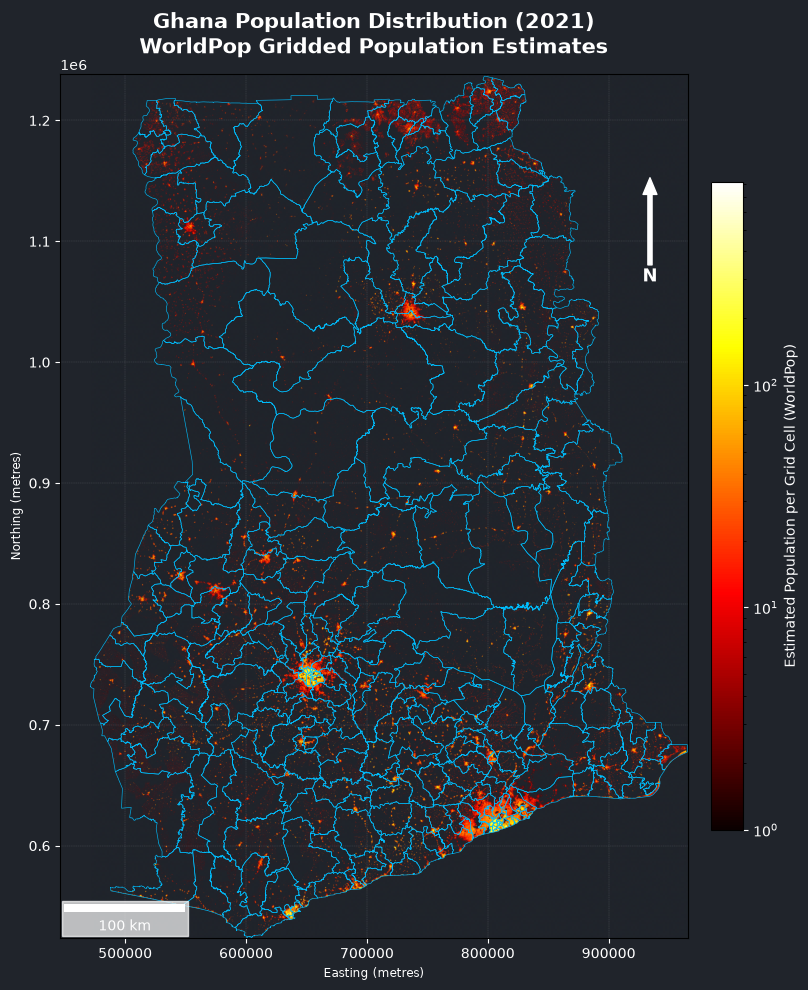

In [107]:
# Create dark hot colormap
dark_cmap = plt.colormaps["hot"].copy()
dark_cmap.set_bad("#20242B")

# Recreate figure
fig, ax = plt.subplots(figsize=(12, 10))

fig.patch.set_facecolor("#20242B")
ax.set_facecolor("#20242B")

# Plot raster again
im = ax.imshow(
    projected_population,
    cmap=dark_cmap,
    norm=LogNorm(
        vmin=1,
        vmax=float(projected_population.max())
    ),
    extent=projected_extent,
    origin="upper"
)

# District boundaries
districts_projected_map.boundary.plot(
    ax=ax,
    color="#00BFFF",
    linewidth=0.45,
    alpha=0.95
)

# Colour bar
cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
cbar.set_label(
    "Estimated Population per Grid Cell (WorldPop)",
    color="white"
)
cbar.ax.tick_params(colors="white")

# Title and labels
ax.set_title(
    "Ghana Population Distribution (2021)\nWorldPop Gridded Population Estimates",
    fontsize=15,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel("Easting (metres)", color="white")
ax.set_ylabel("Northing (metres)", color="white")
ax.tick_params(colors="white")

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.88),
    xytext=(0.94, 0.76),
    xycoords="axes fraction",
    textcoords="axes fraction",
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        width=3,
        headwidth=10
    ),
    ha="center",
    color="white",
    fontsize=13,
    fontweight="bold"
)

# Scale bar
scalebar = ScaleBar(
    dx=1,
    units="m",
    dimension="si-length",
    location="lower left",
    length_fraction=0.20,
    box_alpha=0.7,
    color="white",
    scale_loc="bottom"
)

ax.add_artist(scalebar)

# Grid and layout
ax.grid(
    True,
    linestyle="--",
    linewidth=0.3,
    color="white",
    alpha=0.2
)

plt.tight_layout()
plt.show()

In [124]:
# Ensure output directory exists
output_dir.mkdir(parents=True, exist_ok=True)

# Define final map path
final_map_path = (
    output_dir / "ghana_worldpop_population_heatmap_2021.png"
)

# Save high-resolution map
fig.savefig(
    final_map_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

print("FINAL MAP SAVED SUCCESSFULLY")
print("-" * 40)
print("Resolution: 300 DPI")
print("Format: PNG")

FINAL MAP SAVED SUCCESSFULLY
----------------------------------------
Resolution: 300 DPI
Format: PNG
